# Business view: eacr-2026 metadata pipeline

The Step 2 to Step 4 results rewritten as questions budget owners already ask. Reads `step2/eval.jsonl` and `data/topics/eacr-2026.jsonl`. No model is called.

**Caveat:** one conference, one judge pass, no human check.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PLOT_DIR = ROOT / "data" / "plots" / "step5"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
NAME = "eacr-2026"

ev = json.loads((ROOT / "step2" / "eval.jsonl").read_text().splitlines()[0])
talks, fields = ev["talks"], ev["fields"]
df = pd.read_json(ROOT / "data" / "topics" / f"{NAME}.jsonl", lines=True)
n = len(df)

INK, MUTED, BLUE = "#1f2937", "#6b7280", "#2563eb"

sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 12,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": INK,
        "text.color": INK,
        "axes.edgecolor": "#d1d5db",
        "grid.color": "#e5e7eb",
        "legend.frameon": False,
        "figure.dpi": 110,
        "savefig.dpi": 200,
    },
)


def finish(fig, name):
    sns.despine(fig=fig, left=True)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

## 1. Three questions, three numbers

- **Of what we publish, how much is real?** (precision)
- **How much did we miss?** (recall)
- **Does it make things up?** (hallucination). Lead with this one: trust is the reason for building the system.

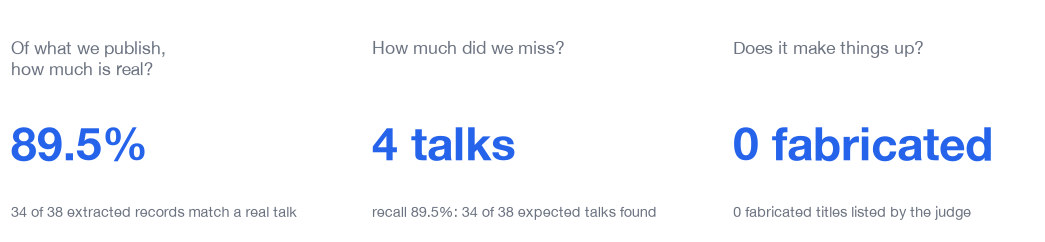

In [2]:
tiles = [
    ("Of what we publish,\nhow much is real?", f"{talks['precision']:.1%}",
     f"{talks['matched']} of {talks['extracted']} extracted records match a real talk"),
    ("How much did we miss?", f"{talks['missed']} talks",
     f"recall {talks['recall']:.1%}: {talks['expected'] - talks['missed']} of {talks['expected']} expected talks found"),
    ("Does it make things up?", f"{talks['fabricated']} fabricated",
     f"{len(ev['fabricated_titles'])} fabricated titles listed by the judge"),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, (question, value, note) in zip(axes, tiles):
    ax.axis("off")
    ax.text(0, 0.88, question, fontsize=11.5, color=MUTED, va="top")
    ax.text(0, 0.40, value, fontsize=30, fontweight="bold", color=BLUE, va="center")
    ax.text(0, 0.05, note, fontsize=9.5, color=MUTED, va="bottom", wrap=True)
fig.savefig(PLOT_DIR / "01_headline.png", bbox_inches="tight", facecolor="white")
plt.show()

## 2. Where it goes wrong

Share of values that are wrong or missing, per field, over matched records. `correct_null` (nothing on the page, nothing extracted) is excluded, as in the judge's own TP/FP/FN definitions. This rate is derived here from the verdict counts in `eval.jsonl`; it is not a metric the judge returns. A field with no scorable values shows n/a.

The real mistakes are the missed and fabricated titles the judge listed.

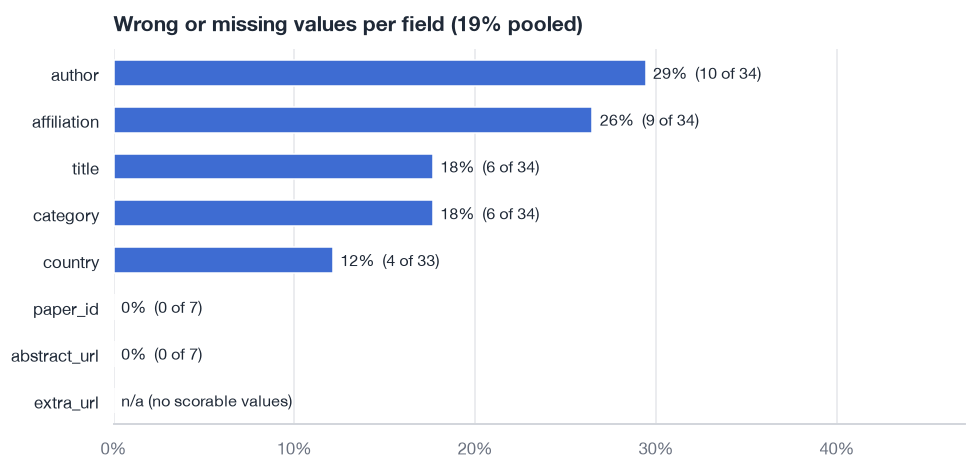

Pooled over 183 scored values in 7 fields; 89 correct_null values excluded.

Missed talks (4):
  - Important roles of selenoproteins and redox biology in cancer
  - Roles of transsulfuration pathway in pancreatic ductal adenocarcinoma
  - Glucocorticoid receptor signaling in breast cancer progression
  - Transcriptome and repertoire profiling of infiltrating γδ T cells to decode tumor escape at single cell resolution

Fabricated talks (0):
  - (none)


In [3]:
rows = []
for f, v in fields.items():
    wrong = v["incorrect"] + v["hallucinated"] + v["missing"]
    rows.append((f, wrong, v["correct"] + wrong, v["correct_null"]))
wr = pd.DataFrame(rows, columns=["field", "wrong", "scored", "excluded"])
scorable = wr[wr["scored"] > 0]
overall = scorable["wrong"].sum() / scorable["scored"].sum()
wr["rate"] = wr["wrong"] / wr["scored"].where(wr["scored"] > 0)
wr = wr.sort_values("rate", ascending=False, na_position="last")

labels = [
    "n/a (no scorable values)" if pd.isna(r) else f"{r:.0%}  ({w} of {s})"
    for r, w, s in zip(wr["rate"], wr["wrong"], wr["scored"])
]

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.barplot(data=wr.fillna({"rate": 0}), x="rate", y="field", color=BLUE, width=0.55, ax=ax)
ax.bar_label(ax.containers[0], labels=labels, padding=5, fontsize=10.5)
ax.set(xlim=(0, wr["rate"].max() * 1.6), xlabel="", ylabel="",
       title=f"Wrong or missing values per field ({overall:.0%} pooled)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
finish(fig, "02_wrong_fields")

print(f"Pooled over {scorable['scored'].sum()} scored values in {len(scorable)} fields; "
      f"{wr['excluded'].sum()} correct_null values excluded.\n")
print(f"Missed talks ({len(ev['missed_titles'])}):")
for t in ev["missed_titles"]:
    print("  -", t)
print(f"\nFabricated talks ({len(ev['fabricated_titles'])}):")
for t in ev["fabricated_titles"] or ["(none)"]:
    print("  -", t)

## 3. What we do not know yet

Records with a non-empty value per field in the extractor output. This is coverage, not correctness.

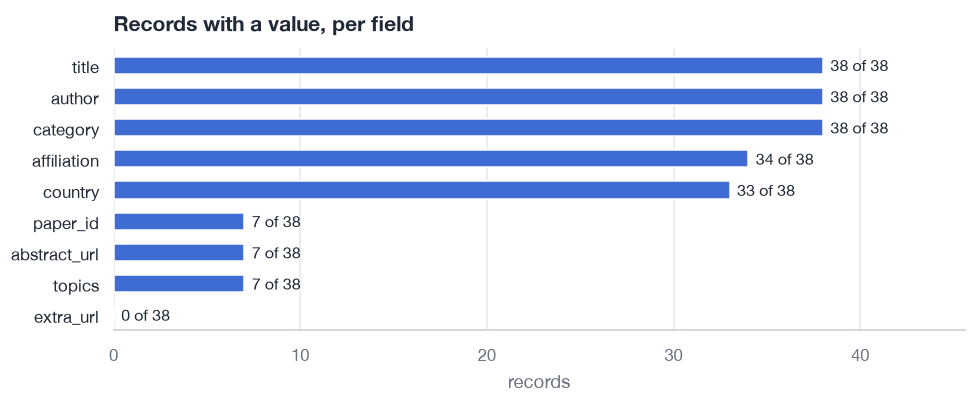

In [4]:
filled = df.apply(lambda s: s.map(lambda v: v is not None and not (isinstance(v, float) and pd.isna(v)) and v != "")).sum()
cov = pd.DataFrame({"field": filled.index, "filled": filled.values}).sort_values("filled", ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.barplot(data=cov, x="filled", y="field", color=BLUE, width=0.55, ax=ax)
ax.bar_label(ax.containers[0], labels=[f"{v} of {n}" for v in cov["filled"]], padding=5, fontsize=10.5)
ax.set(xlim=(0, n * 1.2), xlabel="records", ylabel="", title="Records with a value, per field")
finish(fig, "03_coverage")

## 4. What clean metadata could count later

Dominance (share of talks from one country) is the only popularity signal available, since there are no views or saves. It is computed from the extractor output, so it is unverified: see the caveat printed below the chart. The right panel shows whether authors and topic strings repeat at all, which they would need to for per-topic counts.

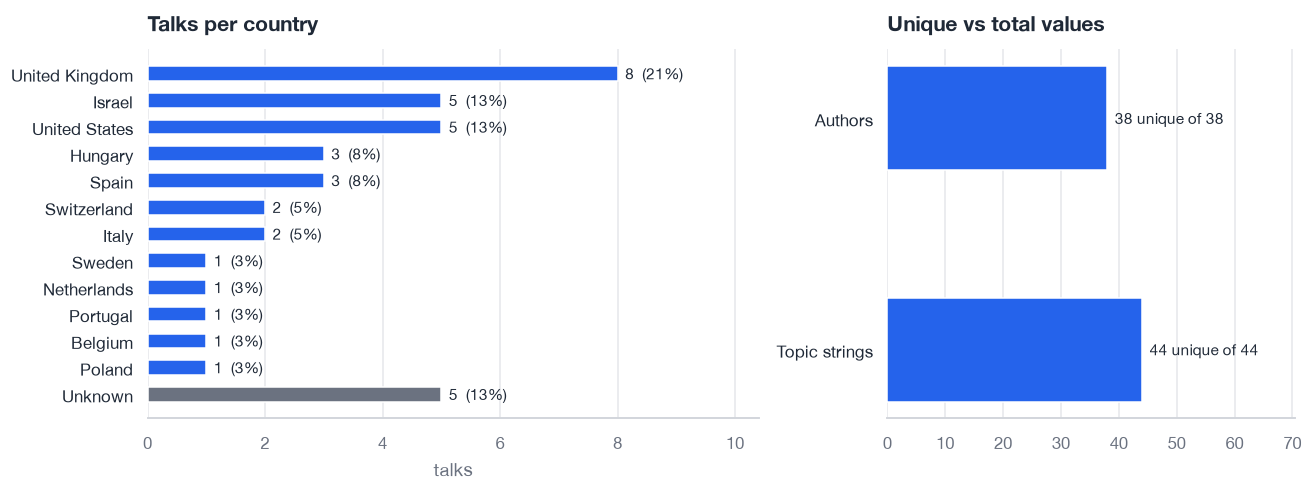

Caveat: the judge marked 4 of 38 extracted records as not a talk, and found 4 missing and 0 incorrect countries among 34 matched records. The shares above include all of these.


In [5]:
country = df["country"].replace("", None).fillna("Unknown")
share = country.value_counts().rename_axis("country").reset_index(name="talks")
share["share"] = share["talks"] / n
share = pd.concat([share[share["country"] != "Unknown"], share[share["country"] == "Unknown"]])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

colors = [MUTED if c == "Unknown" else BLUE for c in share["country"]]
ax1.barh(share["country"], share["talks"], color=colors, height=0.55)
ax1.bar_label(ax1.containers[0], labels=[f"{t}  ({s:.0%})" for t, s in zip(share["talks"], share["share"])],
              padding=5, fontsize=10)
ax1.invert_yaxis()
ax1.set(xlim=(0, share["talks"].max() * 1.3), xlabel="talks", ylabel="", title="Talks per country")
ax1.grid(axis="y", visible=False)

topics = df["topics"].dropna().explode()
uniq = pd.DataFrame({
    "item": ["Authors", "Topic strings"],
    "total": [n, len(topics)],
    "unique": [df["author"].nunique(), topics.nunique()],
})
ax2.barh(uniq["item"], uniq["unique"], color=BLUE, height=0.45)
ax2.bar_label(ax2.containers[0], labels=[f"{u} unique of {t}" for u, t in zip(uniq["unique"], uniq["total"])],
              padding=5, fontsize=10)
ax2.invert_yaxis()
ax2.set(xlim=(0, uniq["unique"].max() * 1.6), xlabel="", ylabel="", title="Unique vs total values")
ax2.grid(axis="y", visible=False)

finish(fig, "04_dominance")

c = fields["country"]
print(f"Caveat: the judge marked {talks['not_a_talk']} of {talks['extracted']} extracted records as not a talk, "
      f"and found {c['missing']} missing and {c['incorrect']} incorrect countries among {talks['matched']} matched records. "
      "The shares above include all of these.")